In [1]:
# =====================================================================
# CELL PURPOSE: Import every library the notebook relies on and define the
# padding-token ID that the masks, embeddings and loss functions all share.
# =====================================================================
import math                      # sqrt/log/exp helpers (attention scaling, positional-encoding frequencies)
import torch                     # core PyTorch: tensors, autograd, devices
import torch.nn as nn            # layer classes: Linear, Embedding, LayerNorm, Dropout, Module, ...
import torch.nn.functional as F  # stateless ops such as cross_entropy

PAD_ID = 0   # integer ID of the <PAD> token; used to build padding masks, to zero its embedding, and to be ignored by the loss

In [2]:
# =====================================================================
# CELL PURPOSE: Define the two attention masks (causal + padding) and the
# sinusoidal positional-encoding layer. Mask convention: True = "may attend".
# =====================================================================

# ---------------- Masks (True = position is allowed to be attended to) ----------------
def causal_mask(T, device=None):
    # Builds a lower-triangular mask so token t can only see tokens 0..t (no peeking at the future).
    # T      : sequence length (number of tokens)
    # device : device (cpu/cuda) on which the mask tensor is created
    # Returns: bool tensor of shape [1, 1, T, T] (broadcastable over batch and heads)
    return torch.tril(torch.ones(T, T, dtype=torch.bool, device=device)).view(1, 1, T, T)


def padding_mask(ids, pad_id=PAD_ID):
    # Marks real tokens as True and <PAD> tokens as False so attention ignores padding.
    # ids    : LongTensor of token IDs, shape [B, T]  (B = batch size, T = sequence length)
    # pad_id : ID of the padding token
    # Returns: bool tensor of shape [B, 1, 1, T] (broadcast over heads and query positions)
    return (ids != pad_id).unsqueeze(1).unsqueeze(2)   # [B,1,1,T]


# ---------------- Positional Encoding (sin/cos) ----------------
class PositionalEncoding(nn.Module):
    # Adds fixed (non-learned) sinusoidal position information to the token embeddings,
    # because attention by itself has no notion of word order.
    def __init__(self, d_model, max_len=512):
        # d_model : embedding dimension (must be even: half sin, half cos)
        # max_len : maximum sequence length the table is precomputed for
        super().__init__()
        assert d_model % 2 == 0, "d_model لازم يكون زوجي"   # d_model must be even: sin goes to even dims, cos to odd dims
        pe = torch.zeros(max_len, d_model)                  # pe  : positional table [max_len, d_model], filled below
        pos = torch.arange(max_len).unsqueeze(1).float()    # pos : position indices 0..max_len-1, shape [max_len, 1]
        # div : frequency scale per sin/cos pair, equals 1 / 10000^(2i/d_model); computed in log space for stability
        div = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(pos * div)                  # even dimensions get sine
        pe[:, 1::2] = torch.cos(pos * div)                  # odd dimensions get cosine
        # register_buffer: saved in state_dict and moved with .to(device), but NOT a trainable parameter
        self.register_buffer("pe", pe.unsqueeze(0))         # final shape [1, max_len, d_model]

    def forward(self, x):
        # x      : token embeddings, shape [B, T, d_model]
        # Returns: x plus the first T rows of the positional table (broadcast over the batch)
        return x + self.pe[:, : x.size(1)]

In [3]:
# =====================================================================
# CELL PURPOSE: Implement Multi-Head Attention, the core Transformer operation.
# It is used for self-attention (encoder/decoder) and cross-attention (decoder over encoder output).
# =====================================================================

# ---------------- Multi-Head Attention ----------------
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, num_heads, dropout=0.0):
        # d_model   : embedding size of the model (input and output feature dimension)
        # num_heads : number of parallel attention heads; d_model must be divisible by it
        # dropout   : probability of dropping attention weights (regularization)
        super().__init__()
        assert d_model % num_heads == 0     # each head gets an equal slice of d_model
        self.h = num_heads                  # h  : number of heads
        self.dk = d_model // num_heads      # dk : dimension of each head
        self.wq = nn.Linear(d_model, d_model)   # projection that produces Queries
        self.wk = nn.Linear(d_model, d_model)   # projection that produces Keys
        self.wv = nn.Linear(d_model, d_model)   # projection that produces Values
        self.wo = nn.Linear(d_model, d_model)   # output projection applied after concatenating the heads
        self.drop = nn.Dropout(dropout)         # dropout applied to the attention probabilities
        self.last_attn = None   # stores the latest attention weights for visualization and inspection

    def _split(self, x):        # [B,T,D] -> [B,h,T,dk]
        # Reshapes the feature dimension into (heads, dk) so every head attends independently.
        # x : tensor of shape [B, T, d_model]
        B, T, _ = x.shape
        return x.view(B, T, self.h, self.dk).transpose(1, 2)

    def forward(self, q_in, kv_in, mask=None):
        # self-attention: q_in = kv_in | cross-attention: kv_in = Encoder output
        # q_in  : tensor that produces the Queries, shape [B, Tq, d_model]
        # kv_in : tensor that produces the Keys and Values, shape [B, Tk, d_model]
        # mask  : bool tensor (True = allowed); positions marked False get -inf before softmax
        Q = self._split(self.wq(q_in))      # Q : queries per head  [B, h, Tq, dk]
        K = self._split(self.wk(kv_in))     # K : keys per head     [B, h, Tk, dk]
        V = self._split(self.wv(kv_in))     # V : values per head   [B, h, Tk, dk]

        # scores : similarity of each query with each key, scaled by sqrt(dk) to keep softmax stable
        scores = Q @ K.transpose(-2, -1) / math.sqrt(self.dk)   # [B,h,Tq,Tk]
        if mask is not None:
            scores = scores.masked_fill(~mask, float("-inf"))   # blocked positions get zero probability
        attn = torch.softmax(scores, dim=-1)    # attn : attention weights; each row sums to 1 over the keys
        self.last_attn = attn.detach()          # keep a copy without gradients for plotting/debugging

        out = self.drop(attn) @ V                                # weighted sum of values  [B,h,Tq,dk]
        B, _, Tq, _ = out.shape
        out = out.transpose(1, 2).contiguous().view(B, Tq, -1)   # merge the heads back to [B, Tq, d_model]
        return self.wo(out)                                      # final output projection

In [4]:
# =====================================================================
# CELL PURPOSE: Define the position-wise Feed-Forward network used in every Transformer block.
# It processes each token independently with two linear layers and a non-linearity.
# =====================================================================

# ---------------- Feed Forward ----------------
class FeedForward(nn.Module):
    def __init__(self, d_model, d_ff, dropout=0.0):
        # d_model : input/output feature size
        # d_ff    : hidden (inner) size, usually 4x d_model
        # dropout : dropout probability applied after the activation
        super().__init__()
        # net : expand d_model -> d_ff, apply GELU, dropout, then project back d_ff -> d_model
        self.net = nn.Sequential(
            nn.Linear(d_model, d_ff), nn.GELU(), nn.Dropout(dropout), nn.Linear(d_ff, d_model)
        )

    def forward(self, x):
        # x : tensor of shape [B, T, d_model]; output has the same shape
        return self.net(x)

In [5]:
# =====================================================================
# CELL PURPOSE: Define the Encoder block: self-attention followed by a feed-forward layer,
# each wrapped with LayerNorm (Pre-LN) and a residual connection.
# =====================================================================

# ---------------- Blocks (Pre-LN: x = x + SubLayer(Norm(x))) ----------------
class EncoderBlock(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, dropout=0.1):
        # d_model   : embedding size
        # num_heads : number of attention heads
        # d_ff      : hidden size of the feed-forward network
        # dropout   : dropout probability used inside attention/FFN and on the residual branches
        super().__init__()
        self.attn = MultiHeadAttention(d_model, num_heads, dropout)   # bidirectional self-attention
        self.ffn = FeedForward(d_model, d_ff, dropout)                # position-wise feed-forward
        self.norm1 = nn.LayerNorm(d_model)   # normalizes the input of the attention sub-layer
        self.norm2 = nn.LayerNorm(d_model)   # normalizes the input of the feed-forward sub-layer
        self.drop = nn.Dropout(dropout)      # dropout on each sub-layer output before the residual add

    def forward(self, x, src_mask=None):
        # x        : input tensor [B, T, d_model]
        # src_mask : padding mask for the source sequence so <PAD> tokens are ignored
        h = self.norm1(x)                                  # h : normalized copy of x
        x = x + self.drop(self.attn(h, h, src_mask))       # self-attention (Q, K, V all come from h) + residual
        x = x + self.drop(self.ffn(self.norm2(x)))         # feed-forward + residual
        return x

In [6]:
# =====================================================================
# CELL PURPOSE: Define the Decoder block. It always has masked self-attention and a feed-forward
# layer, and it can optionally include cross-attention over the Encoder output
# (on for the translation Transformer, off for GPT).
# =====================================================================
class DecoderBlock(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, dropout=0.1, use_cross_attn=False):
        # d_model        : embedding size
        # num_heads      : number of attention heads
        # d_ff           : hidden size of the feed-forward network
        # dropout        : dropout probability
        # use_cross_attn : True = add cross-attention to the Encoder output (Encoder-Decoder model);
        #                  False = decoder-only model such as GPT
        super().__init__()
        self.self_attn = MultiHeadAttention(d_model, num_heads, dropout)  # masked self-attention over target tokens
        self.norm1 = nn.LayerNorm(d_model)                                # norm before self-attention
        self.use_cross = use_cross_attn                                   # remembers whether cross-attention is active
        if use_cross_attn:
            self.cross_attn = MultiHeadAttention(d_model, num_heads, dropout)  # queries from decoder, keys/values from encoder
            self.norm_cross = nn.LayerNorm(d_model)                            # norm before cross-attention
        self.ffn = FeedForward(d_model, d_ff, dropout)   # position-wise feed-forward
        self.norm2 = nn.LayerNorm(d_model)               # norm before the feed-forward
        self.drop = nn.Dropout(dropout)                  # dropout on each sub-layer output

    def forward(self, x, tgt_mask, enc_out=None, src_mask=None):
        # x        : decoder input [B, Tt, d_model]
        # tgt_mask : causal (+ padding) mask for the target sequence
        # enc_out  : Encoder output [B, Ts, d_model]; only needed when use_cross_attn=True
        # src_mask : padding mask of the source sequence, used by cross-attention
        h = self.norm1(x)
        x = x + self.drop(self.self_attn(h, h, tgt_mask))             # Masked Self-Attention
        if self.use_cross:
            h = self.norm_cross(x)
            x = x + self.drop(self.cross_attn(h, enc_out, src_mask))   # Cross-Attention
        x = x + self.drop(self.ffn(self.norm2(x)))                     # Feed Forward
        return x

In [7]:
# =====================================================================
# CELL PURPOSE: Weight-initialization function applied to every sub-module of the models
# via model.apply(...), giving small, stable starting weights.
# =====================================================================
def _init_weights(module, d_model):
    # module  : a single sub-module visited by model.apply (Linear, Embedding, LayerNorm, ...)
    # d_model : embedding size, used to scale the embedding initialization
    if isinstance(module, nn.Linear):
        nn.init.normal_(module.weight, mean=0.0, std=0.02)   # small Gaussian weights (mean = average, std = spread)
        if module.bias is not None:
            nn.init.zeros_(module.bias)                      # biases start at zero
    elif isinstance(module, nn.Embedding):
        nn.init.normal_(module.weight, mean=0.0, std=d_model ** -0.5)   # std = 1/sqrt(d_model)

In [8]:
# =====================================================================
# CELL PURPOSE: Assemble the full Encoder-Decoder Transformer (used for English -> Arabic translation),
# including encode(), decode(), forward() and a greedy_decode() inference method.
# =====================================================================

# ---------------- Full Transformer (Encoder-Decoder) ----------------
class Transformer(nn.Module):
    def __init__(self, src_vocab, tgt_vocab, d_model=128, num_heads=4, d_ff=512,
                 num_layers=2, dropout=0.1, max_len=512, pad_id=PAD_ID):
        # src_vocab  : size of the source vocabulary (number of distinct input tokens)
        # tgt_vocab  : size of the target vocabulary (number of distinct output tokens)
        # d_model    : embedding / hidden size
        # num_heads  : attention heads per attention layer
        # d_ff       : hidden size of the feed-forward networks
        # num_layers : number of stacked encoder blocks AND of decoder blocks
        # dropout    : dropout probability
        # max_len    : maximum sequence length supported by the positional encoding
        # pad_id     : token ID used for padding
        super().__init__()
        self.pad_id = pad_id                 # stored so masks can be built in encode()/decode()
        self.scale = math.sqrt(d_model)      # embeddings are multiplied by sqrt(d_model) before adding positions

        self.src_emb = nn.Embedding(src_vocab, d_model, padding_idx=pad_id)   # source token embeddings
        self.tgt_emb = nn.Embedding(tgt_vocab, d_model, padding_idx=pad_id)   # target token embeddings
        self.pos = PositionalEncoding(d_model, max_len)   # shared sinusoidal positional encoding
        self.drop = nn.Dropout(dropout)                   # dropout applied to embeddings + positions

        self.enc_blocks = nn.ModuleList(   # stack of Encoder blocks
            [EncoderBlock(d_model, num_heads, d_ff, dropout) for _ in range(num_layers)])
        self.enc_norm = nn.LayerNorm(d_model)   # final LayerNorm after the last encoder block (needed with Pre-LN)

        self.dec_blocks = nn.ModuleList(   # stack of Decoder blocks, each with cross-attention enabled
            [DecoderBlock(d_model, num_heads, d_ff, dropout, use_cross_attn=True)
             for _ in range(num_layers)])
        self.dec_norm = nn.LayerNorm(d_model)   # final LayerNorm after the last decoder block
        self.head = nn.Linear(d_model, tgt_vocab, bias=False)   # projects hidden states to target-vocabulary logits

        self.apply(lambda m: _init_weights(m, d_model))   # initialize all sub-modules
        with torch.no_grad():                       # keep the padding embedding at zero
            self.src_emb.weight[pad_id].zero_()
            self.tgt_emb.weight[pad_id].zero_()

    def encode(self, src):
        # src     : source token IDs [B, Ts]
        # Returns : (encoder output [B, Ts, d_model], src_mask [B, 1, 1, Ts])
        src_mask = padding_mask(src, self.pad_id)                          # hide <PAD> tokens from attention
        x = self.drop(self.pos(self.src_emb(src) * self.scale))            # embed, scale, add positions, dropout
        for blk in self.enc_blocks:
            x = blk(x, src_mask)                                           # pass through each encoder block
        return self.enc_norm(x), src_mask

    def decode(self, tgt, enc_out, src_mask):
        # tgt      : decoder input token IDs [B, Tt]
        # enc_out  : encoder output [B, Ts, d_model]
        # src_mask : source padding mask for cross-attention
        T = tgt.size(1)                                                             # T : target length
        tgt_mask = causal_mask(T, tgt.device) & padding_mask(tgt, self.pad_id)      # no future peeking AND no padding
        x = self.drop(self.pos(self.tgt_emb(tgt) * self.scale))                     # embed, scale, add positions, dropout
        for blk in self.dec_blocks:
            x = blk(x, tgt_mask, enc_out, src_mask)
        return self.head(self.dec_norm(x))          # logits [B,T,tgt_vocab]

    def forward(self, src, tgt_in):
        # src    : source token IDs [B, Ts]
        # tgt_in : decoder input IDs [B, Tt] (target shifted right, starting with <BOS>; teacher forcing)
        enc_out, src_mask = self.encode(src)
        return self.decode(tgt_in, enc_out, src_mask)

    @torch.no_grad()
    def greedy_decode(self, src, bos_id, eos_id, max_len=50):
        # Generates a translation token by token, always choosing the most probable next token.
        # src     : source token IDs [B, Ts]
        # bos_id  : ID of <BOS>, the first decoder input
        # eos_id  : ID of <EOS>, which ends a sequence
        # max_len : maximum number of tokens to generate
        self.eval()                                   # disable dropout for inference
        enc_out, src_mask = self.encode(src)          # encode the source once and reuse it every step
        ys = torch.full((src.size(0), 1), bos_id, dtype=torch.long, device=src.device)   # ys : generated tokens so far, starts with <BOS>
        done = torch.zeros(src.size(0), dtype=torch.bool, device=src.device)             # done : which batch items already produced <EOS>
        for _ in range(max_len):
            nxt = self.decode(ys, enc_out, src_mask)[:, -1].argmax(-1)   # nxt : best next token from the last position
            nxt = nxt.masked_fill(done, self.pad_id)                     # finished sequences only receive <PAD>
            ys = torch.cat([ys, nxt.unsqueeze(1)], dim=1)                # append the new token
            done |= nxt == eos_id                                        # mark sequences that just emitted <EOS>
            if done.all():                                               # stop early when all sequences are finished
                break
        return ys

In [10]:
# =====================================================================
# CELL PURPOSE: Define a GPT-style decoder-only language model (predicts the next token),
# with a text-generation method, plus a helper that counts model parameters.
# =====================================================================

# ---------------- GPT (Decoder-only) ----------------
class GPT(nn.Module):
    def __init__(self, vocab_size, d_model=128, num_heads=4, d_ff=512,
                 num_layers=4, dropout=0.1, max_len=256):
        # vocab_size : number of distinct tokens
        # d_model    : embedding / hidden size
        # num_heads  : attention heads per layer
        # d_ff       : hidden size of the feed-forward networks
        # num_layers : number of stacked decoder blocks
        # dropout    : dropout probability
        # max_len    : maximum context length (positional table size and generation window)
        super().__init__()
        self.max_len = max_len                # context window size
        self.scale = math.sqrt(d_model)       # embedding scaling factor
        self.tok = nn.Embedding(vocab_size, d_model)         # token embedding table
        self.pos = PositionalEncoding(d_model, max_len)      # sinusoidal positional encoding
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList(          # decoder-only blocks: no cross-attention
            [DecoderBlock(d_model, num_heads, d_ff, dropout, use_cross_attn=False)
             for _ in range(num_layers)])
        self.norm = nn.LayerNorm(d_model)     # final LayerNorm
        self.head = nn.Linear(d_model, vocab_size, bias=False)   # hidden state -> vocabulary logits

        self.apply(lambda m: _init_weights(m, d_model))
        self.head.weight = self.tok.weight          # Weight Tying: the output layer shares weights with the embedding (after init)

    def forward(self, ids, targets=None):
        # ids     : input token IDs [B, T]
        # targets : optional next-token labels [B, T]; when given, the loss is also computed
        # Returns : (logits [B, T, vocab], loss or None)
        B, T = ids.shape                      # B : batch size, T : sequence length
        assert T <= self.max_len, f"الطول {T} أكبر من max_len={self.max_len}"
        mask = causal_mask(T, ids.device)     # each token sees only itself and earlier tokens
        x = self.drop(self.pos(self.tok(ids) * self.scale))
        for blk in self.blocks:
            x = blk(x, mask)
        logits = self.head(self.norm(x))            # [B,T,vocab]
        loss = None
        if targets is not None:
            # flatten to [B*T, vocab] vs [B*T]; positions equal to PAD_ID are ignored in the loss
            loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), targets.reshape(-1), ignore_index=PAD_ID)
        return logits, loss

    @torch.no_grad()
    def generate(self, ids, max_new_tokens=100, temperature=1.0, top_k=None):
        # Autoregressive sampling: predict a token, append it, repeat.
        # ids            : starting prompt token IDs [B, T0]
        # max_new_tokens : how many new tokens to generate
        # temperature    : <1 makes output more deterministic, >1 more random
        # top_k          : if set, sample only among the k most likely tokens
        self.eval()
        for _ in range(max_new_tokens):
            ctx = ids[:, -self.max_len:]                         # ctx : last max_len tokens (the model's context window)
            logits, _ = self(ctx)
            logits = logits[:, -1, :] / max(temperature, 1e-8)   # keep only the last position; divide by temperature (guard against 0)
            if top_k is not None:
                v, _ = torch.topk(logits, min(top_k, logits.size(-1)))          # v : the top-k logits
                logits = logits.masked_fill(logits < v[:, [-1]], float("-inf")) # drop everything below the k-th best
            probs = torch.softmax(logits, dim=-1)                # probs : probability distribution over the vocabulary
            nxt = torch.multinomial(probs, 1)                    # nxt : one token sampled from probs
            ids = torch.cat([ids, nxt], dim=1)                   # append the sampled token to the sequence
        return ids


def count_params(model):
    # Returns the total number of parameters in the model (numel = number of elements in each tensor)
    return sum(p.numel() for p in model.parameters())

In [11]:
# =====================================================================
# CELL PURPOSE: Define the special tokens and a simple word-level tokenizer that
# splits text into words/punctuation, builds a vocabulary, and converts between text and token IDs.
# =====================================================================
import re                          # regular expressions for tokenization
from collections import Counter    # counts how often each token appears

PAD = "<PAD>"   # padding token: fills shorter sequences up to equal length
BOS = "<BOS>"   # beginning-of-sequence token
EOS = "<EOS>"   # end-of-sequence token
UNK = "<UNK>"   # unknown token: replaces words not found in the vocabulary

SPECIAL_TOKENS = [PAD, BOS, EOS, UNK]   # order defines their fixed IDs: PAD=0, BOS=1, EOS=2, UNK=3


class SimpleTokenizer:
    def __init__(self):
        # Token -> ID and ID -> Token lookup tables (filled by build_vocab)
        self.token_to_id = {}   # maps a token string to its integer ID
        self.id_to_token = {}   # reverse mapping from ID back to the token string

    def tokenize(self, text):
        """
        Splits text into lowercase words and punctuation marks.
        text: the input string.
        Example:
        'Hello, world!' -> ['hello', ',', 'world', '!']
        """
        return re.findall(r"\w+|[^\w\s]", text.lower())

    def build_vocab(self, texts, min_freq=1):
        """
        Builds the vocabulary from a collection of texts.
        texts   : iterable of strings used to collect tokens.
        min_freq: minimum number of occurrences a token needs to be added to the vocabulary.
        """
        counter = Counter()   # counter : token -> number of occurrences across all texts

        for text in texts:
            counter.update(self.tokenize(text))

        # Special tokens get fixed IDs at the start of the vocabulary
        self.token_to_id = {
            token: idx
            for idx, token in enumerate(SPECIAL_TOKENS)
        }

        # Add remaining tokens from most to least frequent
        for token, freq in counter.most_common():
            if freq >= min_freq and token not in self.token_to_id:
                self.token_to_id[token] = len(self.token_to_id)   # next free ID

        # Reverse dictionary (ID -> token)
        self.id_to_token = {
            idx: token
            for token, idx in self.token_to_id.items()
        }

    def encode(self, text, add_bos=False, add_eos=False):
        """
        Converts text into a list of token IDs.
        text   : input string.
        add_bos: if True, prepend the <BOS> ID.
        add_eos: if True, append the <EOS> ID.
        """
        tokens = self.tokenize(text)   # tokens : list of token strings

        ids = [
            self.token_to_id.get(token, self.token_to_id[UNK])   # unknown tokens fall back to the <UNK> ID
            for token in tokens
        ]

        if add_bos:
            ids.insert(0, self.token_to_id[BOS])

        if add_eos:
            ids.append(self.token_to_id[EOS])

        return ids

    def decode(self, ids, skip_special_tokens=True):
        """
        Converts token IDs back into text.
        ids                : list/tensor of token IDs.
        skip_special_tokens: if True, <PAD>/<BOS>/<EOS>/<UNK> are removed from the output.
        """
        tokens = []   # tokens : collected token strings

        for idx in ids:
            # also supports PyTorch tensor elements by converting them to int
            idx = int(idx)
            token = self.id_to_token.get(idx, UNK)   # unknown IDs map to <UNK>

            if skip_special_tokens and token in SPECIAL_TOKENS:
                continue

            tokens.append(token)

        # Join tokens with spaces, then glue punctuation (Latin and Arabic) back to the previous word
        text = " ".join(tokens)
        text = re.sub(r"\s+([,.!?;:،؛؟])", r"\1", text)

        return text

    def __len__(self):
        # Vocabulary size = number of distinct tokens (so len(tokenizer) works)
        return len(self.token_to_id)

    @property
    def pad_id(self):
        # ID of the <PAD> token
        return self.token_to_id[PAD]

    @property
    def bos_id(self):
        # ID of the <BOS> token
        return self.token_to_id[BOS]

    @property
    def eos_id(self):
        # ID of the <EOS> token
        return self.token_to_id[EOS]

    @property
    def unk_id(self):
        # ID of the <UNK> token
        return self.token_to_id[UNK]

In [12]:
# =====================================================================
# CELL PURPOSE: Load the two toy datasets (English->Arabic pairs and GPT texts) and build ONE shared
# vocabulary from all English and Arabic text; then print the vocabulary size and special-token IDs.
# =====================================================================
import csv    # reads the CSV translation file
import json   # reads the JSONL GPT file

# Read the translation data
with open("toy_translation_pairs.csv", encoding="utf-8-sig") as f:   # utf-8-sig strips the BOM that Excel adds
    pairs = list(csv.DictReader(f))   # pairs : list of dicts, one per row, with keys source_en and target_ar

# Read the GPT data
with open("gpt_toy_texts.jsonl", encoding="utf-8") as f:
    gpt_samples = [                        # gpt_samples : list of text strings, one per JSONL line
        json.loads(line)["text"]           # each line is a JSON object; take its "text" field
        for line in f
        if line.strip()                    # skip empty lines
    ]

# Collect English and Arabic texts to build a shared vocabulary
all_texts = []   # all_texts : every sentence used to build the vocabulary

for row in pairs:
    all_texts.append(row["source_en"])   # English source sentence
    all_texts.append(row["target_ar"])   # Arabic target sentence

all_texts.extend(gpt_samples)

tokenizer = SimpleTokenizer()          # tokenizer : the shared tokenizer for both models
tokenizer.build_vocab(all_texts)       # min_freq defaults to 1, so every token is kept

print("Vocabulary size:", len(tokenizer))
print("PAD_ID:", tokenizer.pad_id)
print("BOS_ID:", tokenizer.bos_id)
print("EOS_ID:", tokenizer.eos_id)
print("UNK_ID:", tokenizer.unk_id)

Vocabulary size: 199
PAD_ID: 0
BOS_ID: 1
EOS_ID: 2
UNK_ID: 3


In [13]:
# =====================================================================
# CELL PURPOSE: Sanity-check the tokenizer: encode a sentence with <BOS>/<EOS>,
# decode it back, and show the special-token IDs.
# =====================================================================
text = "I am learning Python"   # text : sample sentence to test with

ids = tokenizer.encode(
    text,
    add_bos=True,    # prepend <BOS>
    add_eos=True     # append <EOS>
)   # ids : list of token IDs for the sentence

print("Original text:", text)
print("Token IDs:", ids)
print("Decoded text:", tokenizer.decode(ids))   # special tokens are skipped by default

print("\nSpecial tokens:")
print("PAD:", tokenizer.pad_id)
print("BOS:", tokenizer.bos_id)
print("EOS:", tokenizer.eos_id)
print("UNK:", tokenizer.unk_id)

Original text: I am learning Python
Token IDs: [1, 9, 18, 12, 20, 2]
Decoded text: i am learning python

Special tokens:
PAD: 0
BOS: 1
EOS: 2
UNK: 3


In [15]:
# =====================================================================
# CELL PURPOSE: Define pad_sequences, which turns a list of variable-length ID lists into one
# rectangular tensor, and demonstrate it on three sample sentences.
# =====================================================================
import torch

def pad_sequences(sequences, pad_id, max_len=None):
    # sequences : list of lists of token IDs (lengths may differ)
    # pad_id    : ID used to fill the empty positions
    # max_len   : optional fixed length; longer sequences are truncated. Default = longest sequence
    # Returns   : LongTensor of shape [len(sequences), max_len]
    if not sequences:
        raise ValueError("sequences cannot be empty")

    if max_len is None:
        max_len = max(len(seq) for seq in sequences)   # pad up to the longest sequence in the batch

    result = torch.full(                 # result : tensor pre-filled with pad_id
        (len(sequences), max_len),
        pad_id,
        dtype=torch.long
    )

    for i, seq in enumerate(sequences):
        seq = seq[:max_len]              # truncate if longer than max_len
        if seq:
            result[i, :len(seq)] = torch.tensor(   # copy the real tokens into the left part of row i
                seq, dtype=torch.long
            )

    return result


sentences = [          # sentences : demo inputs of different lengths
    "hello",
    "how are you",
    "i am learning python"
]

encoded = [            # encoded : each sentence converted to IDs with <BOS> and <EOS>
    tokenizer.encode(s, add_bos=True, add_eos=True)
    for s in sentences
]

batch = pad_sequences(encoded, tokenizer.pad_id)   # batch : padded tensor [3, longest_length]

print("Batch shape:", batch.shape)
print(batch)

Batch shape: torch.Size([3, 6])
tensor([[ 1, 32,  2,  0,  0,  0],
        [ 1, 74, 34, 17,  2,  0],
        [ 1,  9, 18, 12, 20,  2]])


In [17]:
# =====================================================================
# CELL PURPOSE: Show how to instantiate each model with default sizes and fix the special-token ID
# constants. NOTE: `model` is assigned twice, so only the GPT instance remains afterwards.
# =====================================================================
vocab_size = len(tokenizer)   # vocab_size : number of distinct tokens in the shared vocabulary

#Encoder-Decoder Transformer:
model = Transformer(
    src_vocab=vocab_size,        # source vocabulary size
    tgt_vocab=vocab_size,        # target vocabulary size (same shared vocabulary here)
    pad_id=tokenizer.pad_id      # padding ID taken from the tokenizer
)

# GPT Decoder-only:
model = GPT(
    vocab_size=vocab_size        # all other hyperparameters use their default values
)

PAD_ID = tokenizer.pad_id   # padding ID used by the loss and batching code
BOS_ID = tokenizer.bos_id   # <BOS> ID used to start decoding
EOS_ID = tokenizer.eos_id   # <EOS> ID used to stop decoding

In [18]:
# =====================================================================
# CELL PURPOSE: Prepare the GPT training environment: imports, random seeds, device selection,
# and loading the GPT text samples.
# =====================================================================
import csv
import json
import random                              # Python's random generator (shuffling)
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader    # imported but not used later in this notebook

SEED = 42                      # SEED : fixed seed so results are reproducible
random.seed(SEED)              # seed Python's random module
torch.manual_seed(SEED)        # seed PyTorch's random generator

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")   # use the GPU when available
print("Device:", device)

# Read the data files
with open("gpt_toy_texts.jsonl", encoding="utf-8") as f:
    gpt_samples = [
        json.loads(line)["text"]   # take the "text" field of each JSON line
        for line in f if line.strip()
    ]

print("GPT samples:", len(gpt_samples))
print("Example:", gpt_samples[0])
print("Vocabulary size:", len(tokenizer))

Device: cpu
GPT samples: 56
Example: English: hello
Arabic: مرحبا

Vocabulary size: 199


In [19]:
# =====================================================================
# CELL PURPOSE: Split the GPT texts into train/validation (90%/10%) and convert each split
# into one long 1-D tensor of token IDs.
# =====================================================================
random.shuffle(gpt_samples)   # shuffle the samples in place before splitting

split_idx = max(1, int(0.9 * len(gpt_samples)))   # split_idx : index where training ends (at least 1 training sample)
train_texts = gpt_samples[:split_idx]             # train_texts : 90% of the texts
val_texts = gpt_samples[split_idx:]               # val_texts   : remaining 10%

def encode_texts(texts, tokenizer):
    # texts     : list of strings
    # tokenizer : tokenizer used to convert text to IDs
    # Returns   : one 1-D LongTensor with all texts concatenated; each text is wrapped in <BOS> ... <EOS>
    ids = []   # ids : running list of token IDs
    for text in texts:
        ids.extend(
            tokenizer.encode(text, add_bos=True, add_eos=True)
        )
    return torch.tensor(ids, dtype=torch.long)

train_data = encode_texts(train_texts, tokenizer)   # train_data : all training tokens as one tensor
val_data = encode_texts(val_texts, tokenizer)       # val_data   : all validation tokens as one tensor

print("Train tokens:", len(train_data))
print("Validation tokens:", len(val_data))
print("Train example IDs:", train_data[:20].tolist())

Train tokens: 608
Validation tokens: 67
Train example IDs: [1, 5, 4, 8, 14, 7, 12, 6, 4, 15, 60, 2, 1, 5, 4, 122, 7, 8, 42, 6]


In [20]:
# =====================================================================
# CELL PURPOSE: Define get_batch, which samples random windows from the token stream as
# (input, target) pairs for next-token prediction, and test it once.
# =====================================================================
block_size = 32   # block_size : number of tokens in each training sequence (context length)
batch_size = 16   # batch_size : number of sequences per training step

def get_batch(data, batch_size, block_size, device):
    # data       : 1-D tensor of token IDs
    # batch_size : how many windows to sample
    # block_size : length of each window
    # device     : device to move the batch to
    # Returns    : (x, y) where y is x shifted by one token (the next-token target)
    if len(data) <= block_size:
        raise ValueError(
            f"عدد التوكنات ({len(data)}) لازم يكون أكبر من "
            f"block_size ({block_size})."
        )

    starts = torch.randint(                 # starts : random start index of each window
        0, len(data) - block_size, (batch_size,)
    )

    x = torch.stack([                       # x : input tokens          [batch_size, block_size]
        data[i:i + block_size] for i in starts
    ])

    y = torch.stack([                       # y : same window shifted by 1 (what the model must predict)
        data[i + 1:i + block_size + 1] for i in starts
    ])

    return x.to(device), y.to(device)

xb, yb = get_batch(train_data, batch_size, block_size, device)   # xb, yb : a sample input/target batch

print("Input shape:", xb.shape)
print("Target shape:", yb.shape)

Input shape: torch.Size([16, 32])
Target shape: torch.Size([16, 32])


In [21]:
# =====================================================================
# CELL PURPOSE: Create the GPT model used for training and run one forward pass
# to verify the output shape and that the loss is a valid number.
# =====================================================================
vocab_size = len(tokenizer)   # vocabulary size (recomputed for clarity)

gpt = GPT(
    vocab_size=vocab_size,   # number of distinct tokens
    d_model=128,             # embedding/hidden size
    num_heads=4,             # attention heads per layer
    d_ff=512,                # feed-forward hidden size
    num_layers=2,            # number of decoder blocks
    dropout=0.1,             # dropout probability
    max_len=256              # maximum context length
).to(device)                 # move the model to GPU/CPU

logits, loss = gpt(xb, yb)   # logits : predictions [B, T, vocab]; loss : cross-entropy against yb

print("Logits shape:", logits.shape)
print("Loss:", loss.item())

assert logits.shape == (batch_size, block_size, vocab_size)   # shape sanity check
assert torch.isfinite(loss), "Loss غير صالحة!"                 # loss must not be NaN/inf

Logits shape: torch.Size([16, 32, 199])
Loss: 9.078518867492676


In [23]:
# =====================================================================
# CELL PURPOSE: Train the GPT model: set hyperparameters and the optimizer, define a loss-estimation
# helper, then run the training loop with periodic train/validation evaluation.
# =====================================================================
import torch.nn.utils as utils   # provides gradient clipping

learning_rate = 3e-4   # learning_rate : step size of the optimizer
max_iters = 400        # max_iters     : total number of training steps
eval_interval = 50     # eval_interval : evaluate every this many steps

optimizer = torch.optim.AdamW(     # optimizer : AdamW (Adam with decoupled weight decay)
    gpt.parameters(),              # the parameters to update
    lr=learning_rate,
    weight_decay=0.01              # weight_decay : L2-style regularization strength
)

@torch.no_grad()
def estimate_loss(model, data, eval_batches=10):
    # Averages the loss over several random batches (no gradients, eval mode).
    # model        : the model to evaluate
    # data         : token tensor to sample from (train or validation)
    # eval_batches : number of random batches to average
    model.eval()
    losses = []   # losses : loss value of each evaluated batch

    for _ in range(eval_batches):
        x, y = get_batch(
            data, batch_size, block_size, device
        )
        _, loss = model(x, y)
        losses.append(loss.item())

    model.train()   # switch back to training mode
    return sum(losses) / len(losses)


history = {"train": [], "val": []}   # history : (step, loss) records for later inspection/plotting

for step in range(1, max_iters + 1):
    gpt.train()   # enable dropout

    xb, yb = get_batch(                  # xb : inputs, yb : targets for this step
        train_data, batch_size, block_size, device
    )

    optimizer.zero_grad(set_to_none=True)   # clear old gradients (set_to_none is faster/lighter than zeroing)

    logits, loss = gpt(xb, yb)   # forward pass
    loss.backward()              # backward pass: compute gradients

    utils.clip_grad_norm_(gpt.parameters(), max_norm=1.0)   # max_norm : cap the gradient norm to avoid exploding gradients
    optimizer.step()                                        # update the weights

    if step == 1 or step % eval_interval == 0:
        train_loss = estimate_loss(gpt, train_data)   # average loss on training data
        val_loss = estimate_loss(gpt, val_data)       # average loss on validation data

        history["train"].append((step, train_loss))
        history["val"].append((step, val_loss))

        print(
            f"Step {step:3d} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f}"
        )

Step   1 | Train Loss: 1.0240 | Val Loss: 3.5492
Step  50 | Train Loss: 0.9020 | Val Loss: 3.5048
Step 100 | Train Loss: 0.7706 | Val Loss: 3.4489
Step 150 | Train Loss: 0.6575 | Val Loss: 3.5128
Step 200 | Train Loss: 0.5068 | Val Loss: 3.5275
Step 250 | Train Loss: 0.3947 | Val Loss: 3.5756
Step 300 | Train Loss: 0.3184 | Val Loss: 3.6528
Step 350 | Train Loss: 0.2404 | Val Loss: 3.8641
Step 400 | Train Loss: 0.2058 | Val Loss: 3.9647


In [24]:
# =====================================================================
# CELL PURPOSE: Generate a sample text from the trained GPT, then save a checkpoint
# (weights + vocabulary + config) to disk.
# =====================================================================
gpt.eval()   # inference mode (dropout off)

prompt_ids = tokenizer.encode("English:", add_bos=True)   # prompt_ids : starting text as IDs, with <BOS>
prompt = torch.tensor(                                    # prompt : tensor of shape [1, prompt_length]
    [prompt_ids], dtype=torch.long, device=device
)

with torch.no_grad():
    generated_ids = gpt.generate(
        prompt,
        max_new_tokens=30,    # generate up to 30 new tokens
        temperature=0.8,      # <1 = slightly more focused sampling
        top_k=10              # sample only from the 10 most likely tokens
    )

print(tokenizer.decode(generated_ids[0].tolist()))   # convert the first sequence back to text

torch.save({
    "model_state_dict": gpt.state_dict(),     # all learned weights
    "vocab": tokenizer.token_to_id,           # vocabulary so the tokenizer can be rebuilt later
    "config": {                               # hyperparameters needed to rebuild the model
        "d_model": 128,
        "num_heads": 4,
        "d_ff": 512,
        "num_layers": 2,
        "max_len": 256
    }
}, "gpt_toy_checkpoint.pt")                   # output checkpoint file name

english: i work with data arabic: أنا أعمل مع البيانات english: see you tomorrow arabic: أراك غدا english: i like books arabic:


# Transformer Encoder–Decoder Training

In [25]:
# =====================================================================
# CELL PURPOSE: Prepare the translation data: load the CSV, shuffle, split 90%/10%,
# and convert each pair into (source IDs, decoder input IDs, expected output IDs).
# =====================================================================
with open("toy_translation_pairs.csv", encoding="utf-8-sig") as f:
    pairs = list(csv.DictReader(f))   # pairs : rows with source_en / target_ar

random.Random(SEED).shuffle(pairs)    # reproducible shuffle using its own generator seeded with SEED

split_idx = max(1, int(0.9 * len(pairs)))   # split_idx : end of the training portion
train_pairs = pairs[:split_idx]             # 90% for training
val_pairs = pairs[split_idx:]               # 10% for validation


def encode_translation_pairs(rows, tokenizer):
    # rows      : list of dicts with "source_en" and "target_ar"
    # tokenizer : tokenizer used for both languages
    # Returns   : list of (src_ids, decoder_input_ids, decoder_target_ids) tuples
    examples = []   # examples : the encoded training examples

    for row in rows:
        src_ids = tokenizer.encode(          # source: English sentence + <EOS>
            row["source_en"], add_eos=True
        )

        tgt_ids = tokenizer.encode(          # target: <BOS> + Arabic sentence + <EOS>
            row["target_ar"], add_bos=True, add_eos=True
        )

        examples.append((
            src_ids,
            tgt_ids[:-1],  # Decoder input  : target without its last token
            tgt_ids[1:]    # Expected output: target shifted left by one (teacher forcing)
        ))

    return examples

train_examples = encode_translation_pairs(train_pairs, tokenizer)   # encoded training set
val_examples = encode_translation_pairs(val_pairs, tokenizer)       # encoded validation set

print("Training pairs:", len(train_examples))
print("Validation pairs:", len(val_examples))

src_ids, tgt_in_ids, tgt_out_ids = train_examples[0]   # inspect the first training example
print("Source IDs:", src_ids)
print("Target input:", tgt_in_ids)
print("Target output:", tgt_out_ids)

Training pairs: 45
Validation pairs: 5
Source IDs: [9, 18, 12, 20, 2]
Target input: [1, 10, 27, 28]
Target output: [10, 27, 28, 2]


In [26]:
# =====================================================================
# CELL PURPOSE: Define make_transformer_batch, which gathers selected examples, pads them into
# tensors and moves them to the device; then test it on the first 4 examples.
# =====================================================================
def make_transformer_batch(examples, indices, device):
    # examples : list of (src_ids, tgt_in_ids, tgt_out_ids) tuples
    # indices  : which examples to put in this batch
    # device   : device to move the tensors to
    # Returns  : (src, tgt_in, tgt_out) padded LongTensors
    batch = [examples[i] for i in indices]   # batch : the selected examples

    src_list = [item[0] for item in batch]       # source sequences
    tgt_in_list = [item[1] for item in batch]    # decoder input sequences
    tgt_out_list = [item[2] for item in batch]   # expected output sequences

    src = pad_sequences(src_list, PAD_ID)         # pad sources to equal length
    tgt_in = pad_sequences(tgt_in_list, PAD_ID)   # pad decoder inputs
    tgt_out = pad_sequences(tgt_out_list, PAD_ID) # pad targets (PAD positions are ignored by the loss)

    return (
        src.to(device),
        tgt_in.to(device),
        tgt_out.to(device)
    )


src, tgt_in, tgt_out = make_transformer_batch(   # test batch built from examples 0..3
    train_examples, list(range(4)), device
)

print("src:", src.shape)
print("tgt_in:", tgt_in.shape)
print("tgt_out:", tgt_out.shape)

src: torch.Size([4, 5])
tgt_in: torch.Size([4, 4])
tgt_out: torch.Size([4, 4])


In [27]:
# =====================================================================
# CELL PURPOSE: Create the Encoder-Decoder Transformer and run one forward pass on the
# test batch to verify output shapes and that the loss is finite.
# =====================================================================
transformer = Transformer(
    src_vocab=len(tokenizer),   # source vocabulary size
    tgt_vocab=len(tokenizer),   # target vocabulary size (shared vocabulary)
    d_model=128,                # embedding/hidden size
    num_heads=4,                # attention heads per layer
    d_ff=512,                   # feed-forward hidden size
    num_layers=2,               # encoder blocks and decoder blocks count
    dropout=0.1,                # dropout probability
    max_len=256,                # maximum sequence length for positional encoding
    pad_id=PAD_ID               # padding token ID
).to(device)

logits = transformer(src, tgt_in)   # logits : predictions [B, Tt, vocab]

loss = F.cross_entropy(              # loss : cross-entropy between predictions and expected tokens
    logits.reshape(-1, logits.size(-1)),   # flatten to [B*Tt, vocab]
    tgt_out.reshape(-1),                   # flatten targets to [B*Tt]
    ignore_index=PAD_ID                    # do not count padding positions
)

print("Logits shape:", logits.shape)
print("Loss:", loss.item())

assert logits.shape[:2] == tgt_out.shape       # batch and length dimensions must match the targets
assert logits.shape[-1] == len(tokenizer)      # last dimension must be the vocabulary size
assert torch.isfinite(loss)                    # loss must not be NaN/inf

Logits shape: torch.Size([4, 4, 199])
Loss: 5.502902507781982


In [29]:
# =====================================================================
# CELL PURPOSE: Train the translation Transformer for several epochs, tracking average training loss
# and validation loss per epoch.
# =====================================================================
import torch.nn.utils as utils   # gradient clipping utilities

transformer_optimizer = torch.optim.AdamW(   # optimizer for the translation model
    transformer.parameters(),                # parameters to update
    lr=3e-4,                                 # lr : learning rate
    weight_decay=0.01                        # weight_decay : regularization strength
)

def transformer_loss_on_examples(model, examples, batch_size=8):
    # Computes the average loss over a full dataset without updating weights.
    # model      : the model to evaluate
    # examples   : encoded examples (e.g. validation set)
    # batch_size : how many examples to process at a time
    model.eval()
    losses = []   # losses : loss value of each batch

    with torch.no_grad():
        for start in range(0, len(examples), batch_size):
            indices = list(range(                              # indices : examples in the current batch
                start, min(start + batch_size, len(examples))
            ))

            src, tgt_in, tgt_out = make_transformer_batch(
                examples, indices, device
            )

            logits = model(src, tgt_in)

            loss = F.cross_entropy(
                logits.reshape(-1, logits.size(-1)),
                tgt_out.reshape(-1),
                ignore_index=PAD_ID
            )
            losses.append(loss.item())

    model.train()   # restore training mode
    return sum(losses) / len(losses)


epochs = 80       # epochs     : number of full passes over the training set
batch_size = 8    # batch_size : examples per step (NOTE: overrides the batch_size=16 defined earlier for GPT)

transformer_history = {"train": [], "val": []}   # per-epoch average losses (used for plotting)

for epoch in range(1, epochs + 1):
    transformer.train()   # enable dropout

    indices = list(range(len(train_examples)))   # indices : positions of all training examples
    random.shuffle(indices)                      # new random order every epoch

    epoch_losses = []   # epoch_losses : batch losses of the current epoch

    for start in range(0, len(indices), batch_size):
        batch_indices = indices[start:start + batch_size]   # examples of the current batch

        src, tgt_in, tgt_out = make_transformer_batch(
            train_examples, batch_indices, device
        )

        transformer_optimizer.zero_grad(set_to_none=True)   # clear old gradients

        logits = transformer(src, tgt_in)   # forward pass

        loss = F.cross_entropy(
            logits.reshape(-1, logits.size(-1)),
            tgt_out.reshape(-1),
            ignore_index=PAD_ID
        )

        loss.backward()   # compute gradients
        utils.clip_grad_norm_(
            transformer.parameters(), max_norm=1.0   # max_norm : gradient-clipping threshold
        )
        transformer_optimizer.step()   # update weights

        epoch_losses.append(loss.item())

    train_loss = sum(epoch_losses) / len(epoch_losses)   # average training loss for this epoch
    val_loss = transformer_loss_on_examples(             # average validation loss for this epoch
        transformer, val_examples, batch_size
    )

    transformer_history["train"].append(train_loss)
    transformer_history["val"].append(val_loss)

    if epoch == 1 or epoch % 5 == 0:   # print on epoch 1 and every 5th epoch
        print(
            f"Epoch {epoch:02d}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f}"
        )

Epoch 01/80 | Train Loss: 1.2028 | Val Loss: 5.3999
Epoch 05/80 | Train Loss: 0.9849 | Val Loss: 5.6330
Epoch 10/80 | Train Loss: 0.8074 | Val Loss: 5.7305
Epoch 15/80 | Train Loss: 0.6504 | Val Loss: 5.8323
Epoch 20/80 | Train Loss: 0.5165 | Val Loss: 5.9146
Epoch 25/80 | Train Loss: 0.3955 | Val Loss: 6.0115
Epoch 30/80 | Train Loss: 0.3012 | Val Loss: 6.0574
Epoch 35/80 | Train Loss: 0.2384 | Val Loss: 6.2062
Epoch 40/80 | Train Loss: 0.1850 | Val Loss: 6.2374
Epoch 45/80 | Train Loss: 0.1460 | Val Loss: 6.3102
Epoch 50/80 | Train Loss: 0.1195 | Val Loss: 6.3585
Epoch 55/80 | Train Loss: 0.0944 | Val Loss: 6.4018
Epoch 60/80 | Train Loss: 0.0792 | Val Loss: 6.5030
Epoch 65/80 | Train Loss: 0.0663 | Val Loss: 6.5713
Epoch 70/80 | Train Loss: 0.0547 | Val Loss: 6.6137
Epoch 75/80 | Train Loss: 0.0488 | Val Loss: 6.7015
Epoch 80/80 | Train Loss: 0.0493 | Val Loss: 6.7438


In [30]:
# =====================================================================
# CELL PURPOSE: Test the trained translation model: translate one English sentence
# with greedy decoding and print the result.
# =====================================================================
transformer.eval()   # inference mode (dropout off)

test_sentence = "hello"   # test_sentence : English input to translate

src_ids = tokenizer.encode(test_sentence, add_eos=True)   # source IDs, ending with <EOS> as in training

src_tensor = torch.tensor(    # src_tensor : shape [1, source_length] (batch of one)
    [src_ids], dtype=torch.long, device=device
)

with torch.no_grad():
    output_ids = transformer.greedy_decode(
        src_tensor,
        bos_id=BOS_ID,   # token that starts the output
        eos_id=EOS_ID,   # token that ends the output
        max_len=20       # maximum number of tokens to generate
    )

print("Input:", test_sentence)
print("Generated IDs:", output_ids[0].tolist())
print("Prediction:", tokenizer.decode(output_ids[0].tolist()))   # IDs back to Arabic text

Input: hello
Generated IDs: [1, 22, 2]
Prediction: مرحبا


In [31]:
# =====================================================================
# CELL PURPOSE: Save the trained translation Transformer (weights + vocabulary + config) to a checkpoint file.
# =====================================================================
torch.save({
    "model_state_dict": transformer.state_dict(),   # all learned weights
    "vocab": tokenizer.token_to_id,                 # vocabulary needed to rebuild the tokenizer
    "config": {                                     # hyperparameters needed to rebuild the model
        "d_model": 128,
        "num_heads": 4,
        "d_ff": 512,
        "num_layers": 2,
        "max_len": 256
    }
}, "transformer_toy_checkpoint.pt")                 # output checkpoint file name

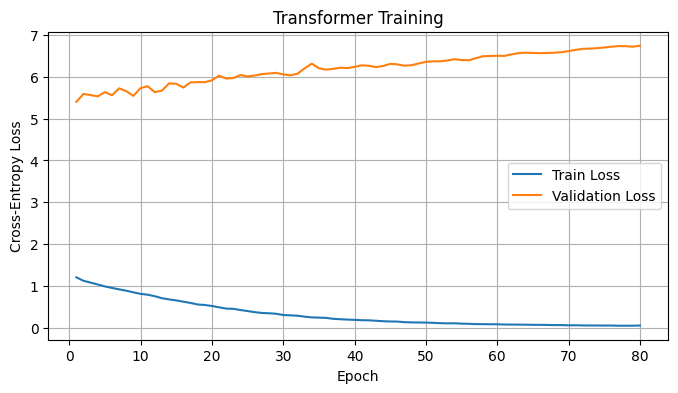

In [32]:
# =====================================================================
# CELL PURPOSE: Plot the translation model's training and validation loss per epoch
# to check learning progress and spot overfitting.
# =====================================================================
import matplotlib.pyplot as plt   # plotting library

plt.figure(figsize=(8, 4))   # figsize : figure size in inches (width, height)
plt.plot(
    range(1, len(transformer_history["train"]) + 1),   # x-axis: epoch numbers 1..N
    transformer_history["train"],                      # y-axis: training loss per epoch
    label="Train Loss"
)
plt.plot(
    range(1, len(transformer_history["val"]) + 1),
    transformer_history["val"],                        # y-axis: validation loss per epoch
    label="Validation Loss"
)
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Transformer Training")
plt.legend()        # show the line labels
plt.grid(True)      # show grid lines
plt.show()          # render the figure